In [1]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.special as sp
from scipy.interpolate import CubicSpline, LinearNDInterpolator
from numba import njit, jit

from tqdm import tqdm
import Mie as mie

In [2]:
# Take refractive index data from file for calculation
#wv_raw, n_raw, k_raw =  np.loadtxt('Wang-4H-o.txt', skiprows= 1, unpack = True)
wv_raw, n_raw, k_raw = np.loadtxt('c-gra-Draine2003.download', skiprows=28, unpack=True)
#wv_raw, n_raw, k_raw = np.loadtxt('sic-Draine1993.download', skiprows=28, unpack=True)

n_raw = np.ones_like(n_raw)
k_raw = 0.1* np.ones_like(n_raw)

#optool data to compare to
#wavelength, ka, ks, g = np.loadtxt('dustkappa-gra-1um.dat', skiprows=24, unpack=True)
wv, m = mie.interp_m(wv_raw, n_raw, k_raw, wv_range = [2e-3, 1000], num_points = 300)
#m = (1.0 + 0.1j) * np.ones_like(m)

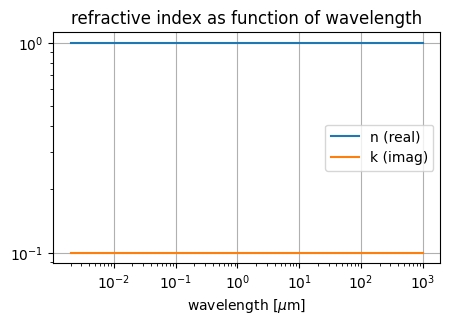

In [3]:
# @title Plot refractive index from file
fig, ax = plt.subplots(1, figsize = [5,3])

ax.plot(wv, m.real, label = 'n (real)')
ax.plot(wv, abs(m.imag), label = 'k (imag)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid()
ax.set_title('refractive index as function of wavelength')
ax.set_xlabel(r'wavelength [$\mu$m]')
ax.legend(loc = 'best')

In [7]:
x_plot = wv
a = 1 # give in micrometers
a = float(a)
y_plot = mie.get_efficiencies(m, x_plot, a)


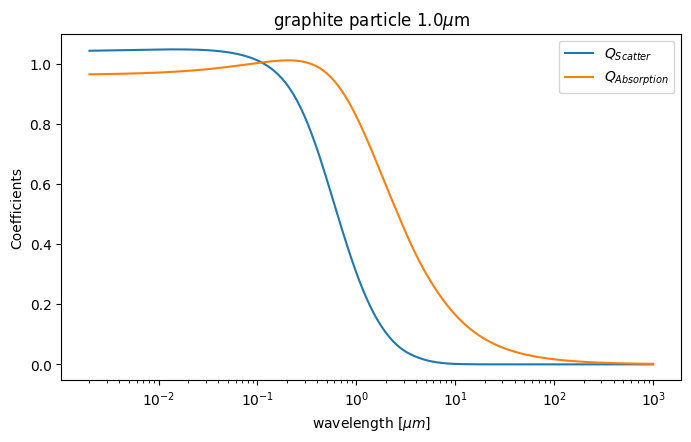

In [8]:
fig, ax = plt.subplots(1, figsize=(8, 4.5))
ax.plot(x_plot, y_plot[0], label = r'$Q_{Scatter}$')
ax.plot(x_plot, y_plot[1]-y_plot[0], label = r'$Q_{Absorption}$')
ax.legend(loc ='best')
ax.set_xlabel(r'wavelength [$\mu m$]')
ax.set_ylabel(r'Coefficients')
ax.set_title(f'graphite particle {a}'+ r'$\mu$m')
#ax.set_xlim(0.4,1)

ax.set_xscale('log')

In [4]:
mie_interp, nd_mie_arr, size_arr, wv_arr =  mie.create_mie_interp([2e-3, 1000], [1e-3, 2.5], wv_raw, n_raw, k_raw, 300, 100)

100%|██████████| 100/100 [00:11<00:00,  8.56it/s]


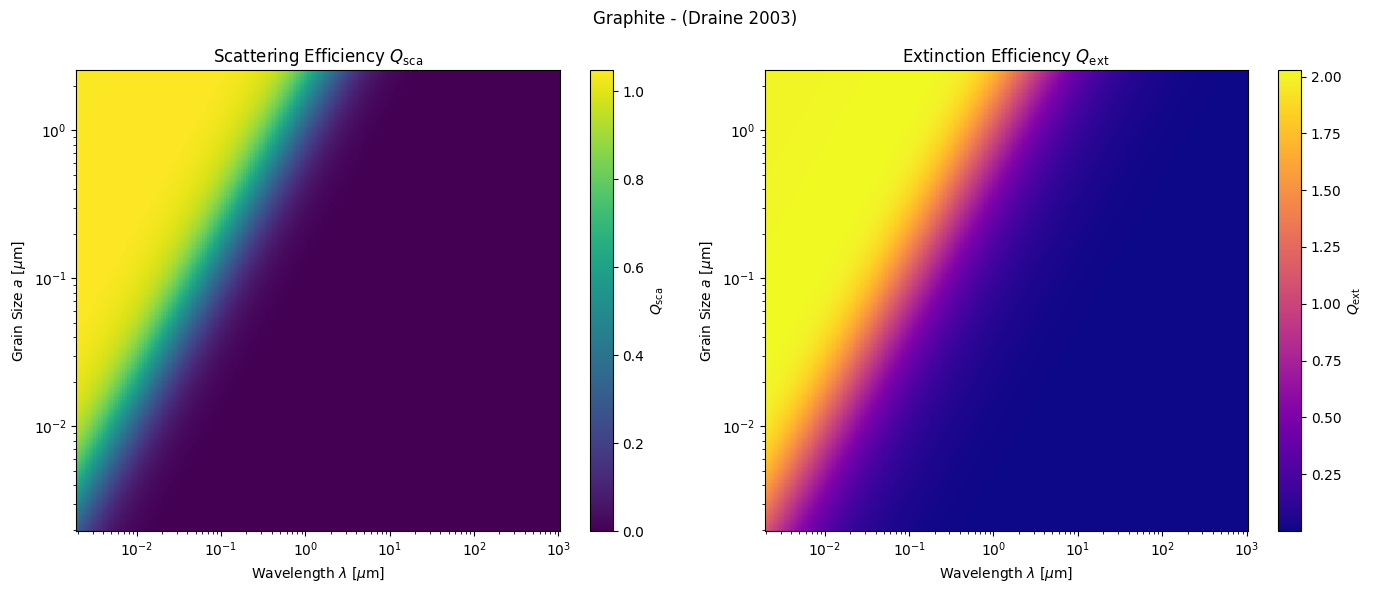

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Define ranges for grain size 'a' and wavelength 'wv'
a_grid = np.logspace(np.log10(2e-3), np.log10(2.5), 200) # 1e-3 to 10 um
wv_grid = np.logspace(np.log10(2e-3), 3, 200) # 1e-3 to 1000 um

# Create 2D meshgrid
A, WV = np.meshgrid(a_grid, wv_grid, indexing='ij')

# Flatten and stack to feed into the interpolator
coords = np.column_stack((A.ravel(), WV.ravel()))
vals = mie_interp(coords)

# Reshape results back to 2D grids
qsca_grid = vals[:, 0].reshape(A.shape)
qext_grid = vals[:, 1].reshape(A.shape)

# Create 2D plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Q_sca
im1 = axes[0].pcolormesh(WV, A, qsca_grid, shading='auto', cmap='viridis')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel(r'Wavelength $\lambda$ [$\mu$m]')
axes[0].set_ylabel(r'Grain Size $a$ [$\mu$m]')
axes[0].set_title(r'Scattering Efficiency $Q_{\rm sca}$')
fig.colorbar(im1, ax=axes[0], label=r'$Q_{\rm sca}$')

# Plot Q_ext
im2 = axes[1].pcolormesh(WV, A, qext_grid, shading='auto', cmap='plasma')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel(r'Wavelength $\lambda$ [$\mu$m]')
axes[1].set_ylabel(r'Grain Size $a$ [$\mu$m]')
axes[1].set_title(r'Extinction Efficiency $Q_{\rm ext}$')
fig.colorbar(im2, ax=axes[1], label=r'$Q_{\rm ext}$')
fig.suptitle('Graphite - (Draine 2003)')

plt.tight_layout()
plt.show()

In [ ]:
def get_rosseland(a, wave, n, T, interpolation, fractions = [0.53, 0.47], species = ['base']):
  '''
  get rosseland mean opacity

  input:
  a         == grain radii [um]   - array
  wave      == wavelength  [um]   - array
  n         == grain distribution - function (eg, MRN)
  T         == temperature        - float
  fractions == species fractions  - list/array
  species   == which dust to use  - list of strings

  '''


  if len(fractions) != len(species) and species[0] != 'base':
    #cant have that mate
    print('Dust fractions list and species list of differing length. Perhaps you missed an entry?')
    return

  # chose dust densities and decide what must have evaporated
  if species[0] == 'base':
    dust_bulk = [2.16] # graphite density in cgs units (Draine 1993, 2003)
    fractions = [1.0]
    #if T > 2273:
    #  fractions[0] = 0.0
#
    #if T > 4000:
    #  fractions[1] = 0.0

  else:
    if T > 2273 and any(species) == 'sic':
      fractions[species == 'sic'] = 0.0

    if T > 4000 and any(species) == 'gra':
      fractions[species == 'gra'] = 0.0


  ###########################
  #     CONSTANTS
  ###########################
  c = 2.99792458e10   # um/s
  h = 6.62607015e-27  # erg s
  k = 1.380649e-16    # erg/K


  #denominator is just what we have to divide by at the end, but here we want to do the integration over wavelength
  denominator = mie.dB_lambda_dT(wave, T) # this will be consolidated into a scalar after integration

  avg_mass = 0.0
  avg_cross_section = 0.0

  for i in range(0, len(fractions)):
    avg_mass += fractions[i]*dust_bulk[i]

    # Evaluate Q_ext for every grain size and wavelength
    A, WV = np.meshgrid(a, wave, indexing='ij')
    coords = np.column_stack((A.ravel(), WV.ravel()))

    vals = interpolation(coords)
    Q_ext = vals[:, 1].reshape(A.shape)  # shape: (len(a), len(wave))

    # Integrate over grain size for each wavelength
    avg_cross_section += np.trapezoid(Q_ext * n(a)[:, None] * a[:, None]**2, a, axis=0)
    #avg_cross_section += np.trapezoid(mie_interp(wv,a) *n(a)*a**2, a)

  avg_mass *= np.trapezoid(n(a)*a**3, a)
  #print(0.75 *avg_cross_section / avg_mass)

  denominator_new = np.trapezoid(denominator* (avg_mass/avg_cross_section), wave)/0.75
  numerator = np.trapezoid(mie.dB_lambda_dT(wave, T), wave)


  return 1e4 *numerator / denominator_new # the factor of 1e4 comes from conversion to cgs from um gs

In [ ]:
def get_planck(a, wave, n, T, interpolation, fractions = [0.53, 0.47], species = ['base']):
  '''
  get planck mean opacity

  input:
  a         == grain radii [um]   - array
  wave      == wavelength  [um]   - array
  n         == grain distribution - function (eg, MRN)
  T         == temperature        - float
  fractions == species fractions  - list/array
  species   == which dust to use  - list of strings

  '''


  if len(fractions) != len(species) and species[0] != 'base':
    #cant have that mate
    print('Dust fractions list and species list of differing length. Perhaps you missed an entry?')
    return

  # chose dust densities and decide what must have evaporated
  if species[0] == 'base':
    dust_bulk = [2.16] # graphite density in cgs units (Draine 1993, 2003)
    fractions = [1.0]


  else:
    if T > 2273 and any(species) == 'sic':
      fractions[species == 'sic'] = 0.0

    if T > 4000 and any(species) == 'gra':
      fractions[species == 'gra'] = 0.0


  ###########################
  #     CONSTANTS
  ###########################
  c = 2.99792458e10   # um/s
  h = 6.62607015e-27  # erg s
  k = 1.380649e-16    # erg/K


  #denominator is just what we have to divide by at the end, but here we want to do the integration over wavelength
  B = mie.B_lambda(wave, T) # this will be consolidated into a scalar after integration

  avg_mass = 0.0
  avg_cross_section = 0.0

  for i in range(0, len(fractions)):
    avg_mass += fractions[i]*dust_bulk[i]

    # Evaluate Q_ext for every grain size and wavelength
    A, WV = np.meshgrid(a, wave, indexing='ij')
    coords = np.column_stack((A.ravel(), WV.ravel()))

    vals = interpolation(coords)
    Q_ext = vals[:, 1].reshape(A.shape)  # shape: (len(a), len(wave))

    # Integrate over grain size for each wavelength
    avg_cross_section += np.trapezoid(Q_ext * n(a)[:, None] * a[:, None]**2, a, axis=0)

  avg_mass *= np.trapezoid(n(a)*a**3, a)

  # Correct integration and division
  numerator = np.trapezoid(avg_cross_section * B, wave) * 0.75 / avg_mass
  denominator = np.trapezoid(B, wave, axis=0)

  # 1e4 factor is the correct scale to convert from (um^2 / (g/cm^3 * um^3)) to (cm^2/g)
  return 1e4 * numerator / denominator

def get_planck_flipped(a, wave, n, T, interpolation, fractions = [0.53, 0.47], species = ['base']):
  '''
  get planck mean opacity

  input:
  a         == grain radii [um]   - array
  wave      == wavelength  [um]   - array
  n         == grain distribution - function (eg, MRN)
  T         == temperature        - float
  fractions == species fractions  - list/array
  species   == which dust to use  - list of strings

  '''


  if len(fractions) != len(species) and species[0] != 'base':
    #cant have that mate
    print('Dust fractions list and species list of differing length. Perhaps you missed an entry?')
    return

  # chose dust densities and decide what must have evaporated
  if species[0] == 'base':
    dust_bulk = [2.16] # graphite density in cgs units (Draine 1993, 2003)
    fractions = [1.0]


  else:
    if T > 2273 and any(species) == 'sic':
      fractions[species == 'sic'] = 0.0

    if T > 4000 and any(species) == 'gra':
      fractions[species == 'gra'] = 0.0


  ###########################
  #     CONSTANTS
  ###########################
  c = 2.99792458e10   # um/s
  h = 6.62607015e-27  # erg s
  k = 1.380649e-16    # erg/K


  #denominator is just what we have to divide by at the end, but here we want to do the integration over wavelength
  B = mie.B_lambda(wave, T) # this will be consolidated into a scalar after integration

  avg_mass = 0.0
  avg_cross_section = 0.0

  for i in range(0, len(fractions)):
    avg_mass += fractions[i]*dust_bulk[i]

    # Evaluate Q_ext for every grain size and wavelength
    A, WV = np.meshgrid(a, wave, indexing='ij')
    coords = np.column_stack((A.ravel(), WV.ravel()))

    vals = interpolation(coords)
    Q_ext = vals[:, 1].reshape(A.shape)  # shape: (len(a), len(wave))

    # Integrate over grain size for each wavelength
    avg_cross_section += np.trapezoid(Q_ext * B, wave, axis = 1)

  avg_mass *= np.trapezoid(n(a)*a**3, a)

  # Correct integration and division
  numerator = np.trapezoid(avg_cross_section * n(a) * a**2, a, axis=0)* 0.75 / avg_mass
  denominator = np.trapezoid(B, wave, axis=0)

  # 1e4 factor is the correct scale to convert from (um^2 / (g/cm^3 * um^3)) to (cm^2/g)
  return 1e4 * numerator / denominator

In [ ]:
mie_interp, nd_mie_arr, beae, asd =  mie.create_mie_interp([1e-3, 1000], [1e-3, 20], wv_raw, n_raw, k_raw, 500, 60)

100%|██████████| 60/60 [02:42<00:00,  2.70s/it]


In [ ]:
wv, m = mie.interp_m(wv_raw, n_raw, k_raw, [2e-3, 1000], 500)
a = np.logspace(np.log10(1e-3), np.log10(3), 40)
temp_plot = np.logspace(np.log10(10),np.log10(3000000), 100)
k_plot = np.zeros(len(temp_plot))
kr_plot = np.zeros(len(temp_plot))
kp_plot = np.zeros(len(temp_plot))

for i in range(0, len(temp_plot)):
  k_plot[i] = get_planck(a, wv, mie.MRN, temp_plot[i], mie_interp)
  kp_plot[i] = get_planck_flipped(a, wv, mie.MRN, temp_plot[i], mie_interp)
  kr_plot[i] = get_rosseland(a, wv, mie.MRN, temp_plot[i], mie_interp)


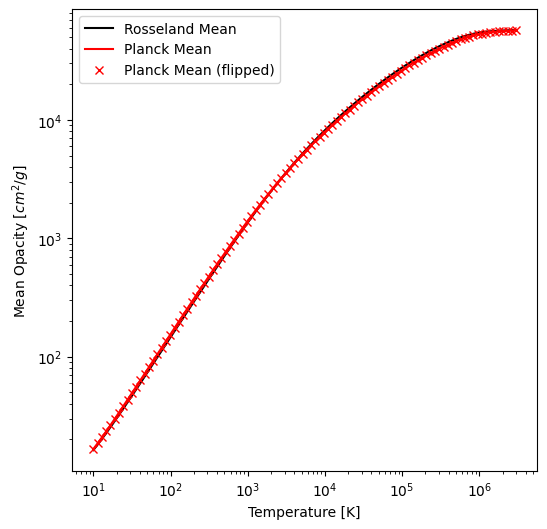

In [ ]:
fig, ax = plt.subplots(1, figsize = [6,6])

#ax.plot(temp_plot, k_plot)
ax.plot(temp_plot, kr_plot, label = r'Rosseland Mean', color = 'black')
ax.plot(temp_plot, k_plot, label = r'Planck Mean', color = 'red')
ax.plot(temp_plot, kp_plot, 'x',label = r'Planck Mean (flipped)', color = 'red')
ax.set_title('')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Mean Opacity [$cm^2/g$]')
ax.set_yscale('log')
ax.set_xscale('log')

ax.legend(loc = 'upper left')

In [ ]:
wv, m = mie.interp_m(wv_raw, n_raw, k_raw, [2e-3, 1000], 500)

points = np.logspace(np.log10(5e-3), np.log10(20), 6)

temp_plot = np.logspace(np.log10(10),np.log10(1000000), 1000)
k_plot = np.zeros([len(temp_plot),5])
for j in range(0, 5):
  for i in range(0, len(temp_plot)):
    # Pass a lambda function to preserve the cutoff bounds while allowing get_rosseland to evaluate over the radius array
    n_dist = lambda r: mie.MRN(r, cutoff_low=points[j], cutoff_high=points[j+1])
    k_plot[i][j] = get_rosseland(np.logspace(np.log10(points[j]), np.log10(points[j+1]), 20), wv, n_dist, temp_plot[i], mie_interp)

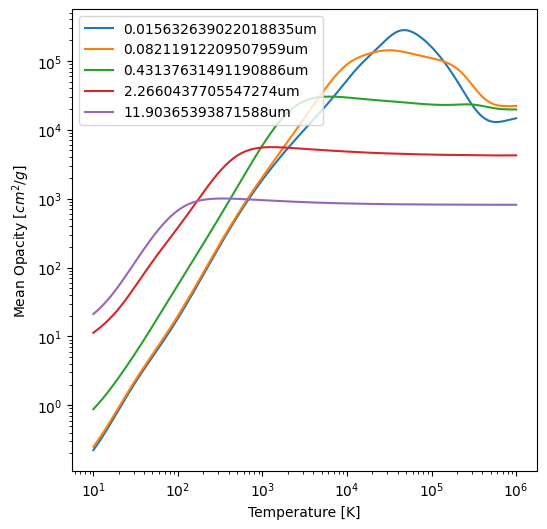

In [ ]:
fig, ax = plt.subplots(1, figsize = [6,6])

#ax.plot(temp_plot, k_plot)



lab = ''
ax.plot(temp_plot, k_plot[:,0], label = f'{0.5* (points[1] + points[0])}um')

for i in range(1,4):
  ax.plot(temp_plot, k_plot[:,i], label = f'{0.5*(points[i+1] +points[i])}um')
  #ax.axvline(2.898e-3 * 0.5e6 / (points[i+1] +points[i]))

ax.plot(temp_plot, k_plot[:,4], label = f'{0.5*(points[5] +points[4])}um')
#ax.axvline(2.898e-3 * 1e6 / (points[5] +points[4]))
#ax.set_title(f'bins of width {4}um')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Mean Opacity [$cm^2/g$]')
ax.set_yscale('log')
ax.set_xscale('log')

ax.legend(loc = 'upper left')

In [ ]:
2.898e-3 * 1e6 /8

362.25


4 slices
Mass fractions: [0.05515 0.12166 0.26456 0.55862]
Sum of fractions: 1.0

32 slices
Mass fractions: [0.00367 0.0054  0.00595 0.00655 0.00722 0.00796 0.00877 0.00967 0.01065
 0.01174 0.01293 0.01425 0.01571 0.01731 0.01907 0.02102 0.02316 0.02552
 0.02813 0.031   0.03416 0.03764 0.04148 0.04571 0.05037 0.0555  0.06117
 0.0674  0.07428 0.08185 0.0902  0.07456]
Sum of fractions: 1.0

48 slices
Mass fractions: [0.00157 0.00346 0.00369 0.00393 0.0042  0.00448 0.00478 0.0051  0.00544
 0.0058  0.00619 0.0066  0.00704 0.00751 0.00802 0.00855 0.00912 0.00974
 0.01039 0.01108 0.01182 0.01261 0.01346 0.01436 0.01532 0.01634 0.01743
 0.0186  0.01984 0.02117 0.02259 0.0241  0.02571 0.02743 0.02926 0.03122
 0.03331 0.03553 0.03791 0.04044 0.04315 0.04603 0.04911 0.0524  0.0559
 0.05964 0.06363 0.03504]
Sum of fractions: 1.0


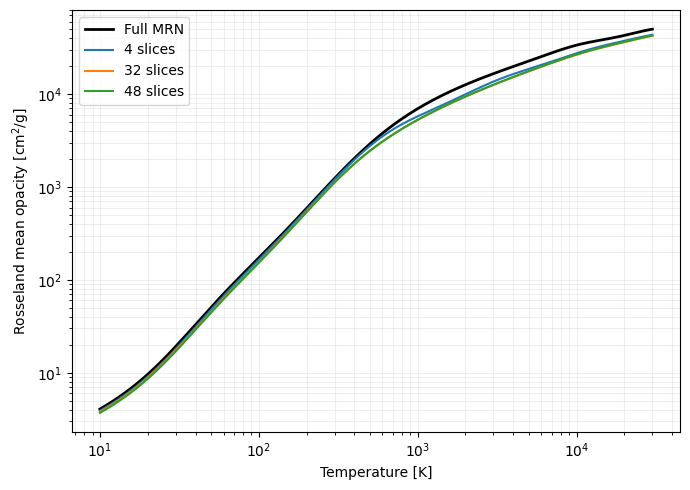

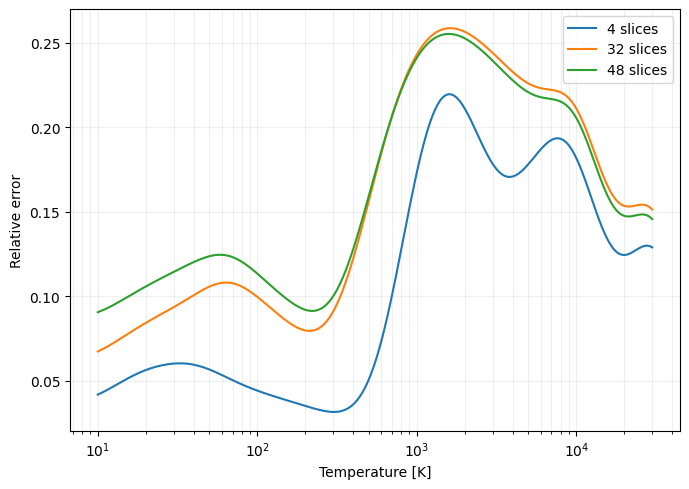

In [ ]:
# Use the existing notebook variables
wave = wv
a_min, a_max = 5e-3, 2.5
T_grid = np.logspace(np.log10(10), np.log10(30000), 200)

# Grain-size grid for the full MRN distribution
a_full = np.logspace(np.log10(a_min), np.log10(a_max), 300)

# Reference: Rosseland mean of the full MRN distribution
k_full = np.array([
    get_rosseland(a_full, wave, mie.MRN, T, mie_interp)
    for T in T_grid
])


def rosseland_by_slices(n_slices, points_per_slice=100):
    """
    Calculate the Rosseland mean in each log-spaced grain-size slice,
    then combine the results using the slice mass fractions.
    """
    edges = np.logspace(np.log10(a_min), np.log10(a_max), n_slices + 1)

    k_slices = np.zeros((len(T_grid), n_slices))
    slice_masses = np.zeros(n_slices)

    for i in range(n_slices):
        # Include each slice's exact endpoints
        a_slice = np.logspace(np.log10(edges[i]), np.log10(edges[i + 1]), points_per_slice)

        # MRN mass is proportional to integral n(a) * a**3 da
        slice_masses[i] = np.trapezoid(mie.MRN(a_slice) * a_slice**3, a_slice)

        # Calculate a Rosseland mean independently for this slice
        for j, T in enumerate(T_grid):
            k_slices[j, i] = get_rosseland(a_slice, wave, mie.MRN, T, mie_interp)

    # Convert slice masses into fractions of the total dust mass
    mass_fractions = slice_masses / np.sum(slice_masses)

    # Mass-weighted harmonic sum of slice Rosseland means (axis=1 to preserve temperature grid)
    k_weighted = np.sum((mass_fractions[None, :]*k_slices), axis=1)

    return k_slices, mass_fractions, k_weighted


# Compare different numbers of slices
results = {}

for n_slices in [4, 32, 48]:
    k_slices, f_mass, k_weighted = rosseland_by_slices(n_slices, int(100/n_slices))

    results[n_slices] = {
        "slice_opacities": k_slices,
        "mass_fractions": f_mass,
        "weighted_sum": k_weighted,
    }

    print(f"\n{n_slices} slices")
    print("Mass fractions:", np.round(f_mass, 5))
    print("Sum of fractions:", f_mass.sum())


# Plot the full distribution and the mass-weighted sums
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(T_grid, k_full, color="black", lw=2,
        label="Full MRN")

for n_slices, result in results.items():
    ax.plot(T_grid, result["weighted_sum"], label=f"{n_slices} slices")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"Rosseland mean opacity [cm$^2$/g]")
ax.legend()
ax.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()


# Relative error of the mass-weighted sum
fig, ax = plt.subplots(figsize=(7, 5))

for n_slices, result in results.items():
    relative_error = np.abs(
        result["weighted_sum"] - k_full
    ) / np.abs(k_full)

    ax.plot(T_grid, relative_error, label=f"{n_slices} slices")

ax.set_xscale("log")
#ax.set_yscale("log")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel("Relative error")
ax.legend()
ax.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()